# Computer Vision Lab 07: Geometric Transformations, Perspective Correction, Camera Calibration & 3D Reconstruction

**Institution:** National University of Computer & Emerging Sciences (FAST-NUCES), Karachi  
**Department:** Department of Artificial Intelligence  
**Student Name:** Muhammad John Raza  
**Roll Number:** 23k-0069  
**Course Instructor:** Talha Shahid  

---

## Lab Overview & Table of Contents
1. **Q1: Image Transformations**
   - *(a)* 2D Transformations (Translation, Rotation, Scaling, Shearing)
   - *(b)* 3D Transformation (Object rotation & translation along X, Y, Z axes)
   - *(c)* 2D Homogeneous Coordinates & Theoretical Importance in Computer Vision
   - *(d)* Affine Transformation & Line Straightness Invariance (Proof & Demo)
   - *(e)* Projective Transformation (Homography) on Slanted Book
2. **Q2: Perspective Correction (Unwarping)**
   - Classic Document Rectification via Inverse Homography Mapping
3. **Q3: Undistort Live Camera Feed**
   - Checkerboard Camera Calibration ($K$ and $D$) & Real-Time Feed Undistortion (`cv2.undistort`)
4. **Q4: Build a 3D Model from Images Using COLMAP**
   - Feature Detection, Matching, Camera Pose Estimation & 3D Reconstruction (Point Cloud + Mesh)


## 0. Setup and Environment Configuration

In [1]:
import os
import glob
import json
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import open3d as o3d
from IPython.display import Image, display

print(f"OpenCV Version: {cv2.__version__}")
print(f"NumPy Version:  {np.__version__}")
print(f"Open3D Version: {o3d.__version__}")


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
OpenCV Version: 4.13.0
NumPy Version:  2.3.5
Open3D Version: 0.20.0


---
## Q1: Image Transformations

### Q1(a): 2D Transformations (Translation, Rotation, Scaling, Shearing)
**Mathematical Formulations:**
1. **Translation:** Shifts image coordinates by $(t_x, t_y)$:
   $$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} x \\ y \end{bmatrix} + \begin{bmatrix} t_x \\ t_y \end{bmatrix}$$
2. **Rotation:** Rotates coordinates about center $(c_x, c_y)$ by angle $\theta$:
   $$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix} \begin{bmatrix} x - c_x \\ y - c_y \end{bmatrix} + \begin{bmatrix} c_x \\ c_y \end{bmatrix}$$
3. **Scaling:** Scales dimensions along axes by $(s_x, s_y)$:
   $$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} s_x & 0 \\ 0 & s_y \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix}$$
4. **Shearing:** Distorts shapes parallel to an axis proportionally to the orthogonal coordinate:
   $$\text{Horizontal Shear: } \begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} 1 & sh_x \\ 0 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \end{bmatrix}$$



--- Running Q1(a): 2D Image Transformations ---


  -> Saved 2D transformation visualization: outputs\q1a_2d_transformations.png


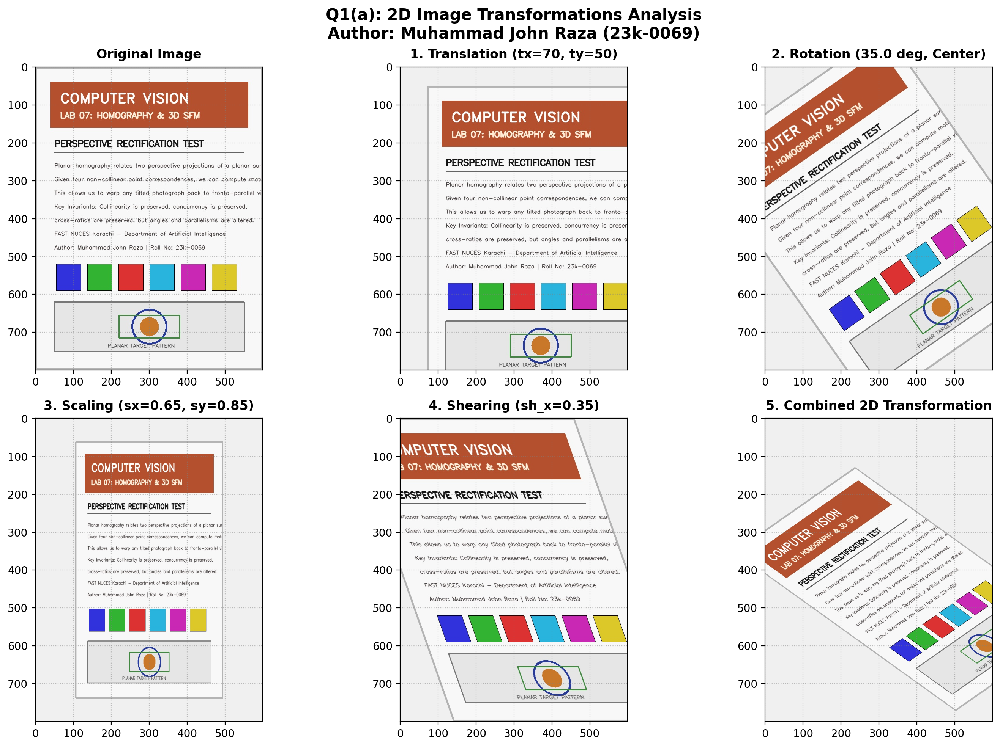

In [2]:
# Run Q1(a): 2D Image Transformations
import task1_image_transformations as t1

fig_q1a = t1.run_q1a_2d_transformations()
display(Image(filename=fig_q1a))


### Q1(b): 3D Transformations (Object Rotation & Translation along X, Y, Z)
**Mathematical Formulation:**
In Euclidean 3-space $\mathbb{R}^3$, an object's rigid body transformation is parameterized by a rotation matrix $R \in SO(3)$ and a translation vector $T \in \mathbb{R}^3$:
$$P' = R P + T$$

Where $R$ is composed of elemental Euler rotations about the canonical axes:
$$R_x(\alpha) = \begin{bmatrix} 1 & 0 & 0 \\ 0 & \cos\alpha & -\sin\alpha \\ 0 & \sin\alpha & \cos\alpha \end{bmatrix}, \quad
R_y(\beta) = \begin{bmatrix} \cos\beta & 0 & \sin\beta \\ 0 & 1 & 0 \\ -\sin\beta & 0 & \cos\beta \end{bmatrix}, \quad
R_z(\gamma) = \begin{bmatrix} \cos\gamma & -\sin\gamma & 0 \\ \sin\gamma & \cos\gamma & 0 \\ 0 & 0 & 1 \end{bmatrix}$$



--- Running Q1(b): 3D Object Transformations ---


  -> Saved 3D transformation visualization: outputs\q1b_3d_transformations.png


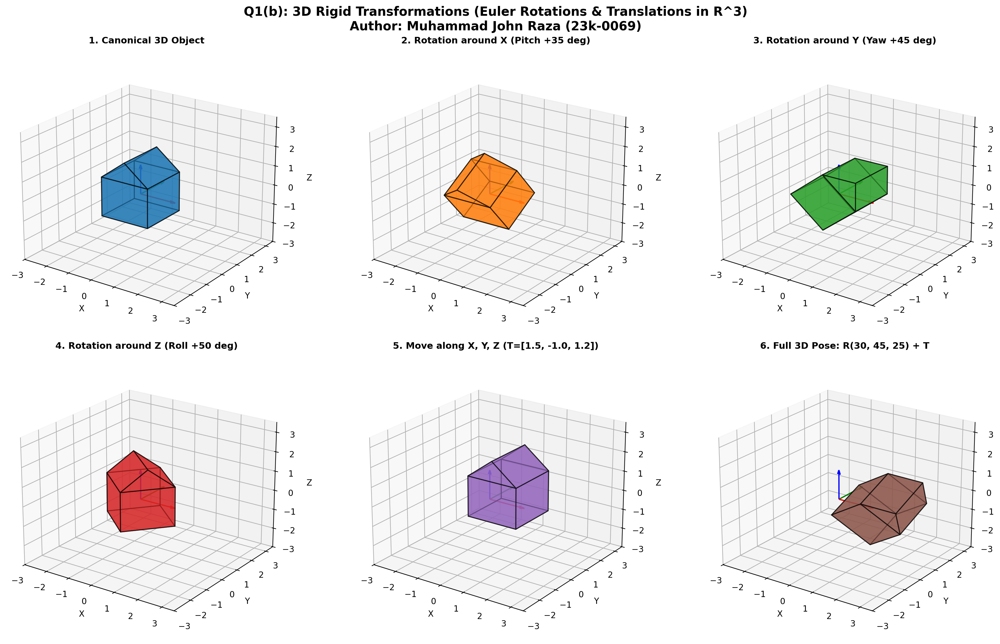

In [3]:
# Run Q1(b): 3D Object Transformations
fig_q1b = t1.run_q1b_3d_transformations()
display(Image(filename=fig_q1b))


### Q1(c): Homogeneous Coordinates & Theoretical Importance in Computer Vision

**Representation:**
A 2D Euclidean point $(x, y) \in \mathbb{R}^2$ is represented in projective space $\mathbb{P}^2$ as a 3D homogeneous coordinate column vector:
$$\mathbf{X} = \begin{bmatrix} x \\ y \\ 1 \end{bmatrix} \quad \sim \quad \begin{bmatrix} w x \\ w y \\ w \end{bmatrix} \quad (w \ne 0)$$
To recover Cartesian coordinates (dehomogenization):
$$x = \frac{X}{W}, \quad y = \frac{Y}{W}$$

**Why the Extra Coordinate is Essential in Computer Vision:**
1. **Linearization of Affine & Projective Transformations:** In Cartesian coordinates, translation $x' = x + t$ is an addition, preventing representation as a $2\times 2$ matrix multiplication. In homogeneous coordinates, translation becomes a linear $3\times 3$ matrix multiplication.
2. **Matrix Composition (Chaining):** Any sequence of translations, rotations, scalings, shears, and homographies can be multiplied into a single composite $3\times 3$ matrix $M = T_k \cdots T_1$. Any pixel is transformed with one matrix-vector multiplication $p' = M p$.
3. **Representation of Points and Lines at Infinity (Ideal Points):** In Euclidean geometry, parallel lines never intersect. In projective geometry $\mathbb{P}^2$, parallel lines intersect at an ideal point where $W = 0$ ($[d_x, d_y, 0]^T$). In camera projections, these points at infinity project to finite **vanishing points** on the horizon.
4. **Pinhole Camera Central Perspective Projection:** Central perspective projection maps 3D world points to 2D pixel coordinates via:
   $$\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = \mathbf{K} [\mathbf{R} \mid \mathbf{t}] \begin{bmatrix} X_w \\ Y_w \\ Z_w \\ 1 \end{bmatrix}$$
   The homogeneous scale factor $\lambda$ corresponds to depth $Z$, naturally capturing perspective foreshortening.


In [4]:
# Run Q1(c): Homogeneous Coordinates Numerical Demonstration
t1.run_q1c_homogeneous_coordinates()



--- Running Q1(c): Homogeneous Coordinates Analysis ---
Q1(c) HOMOGENEOUS COORDINATES IN COMPUTER VISION: FORMAL EXPLANATION
1. REPRESENTATION:
   - Euclidean 2D Point: (x, y) = (145.0, 280.0)
   - Canonical Homogeneous Coordinate: [x, y, 1]^T = [145.0, 280.0, 1.0]^T
   - Equivalence under scale lambda=3.5:
     [507.5, 980.0, 3.5]^T
     Dehomogenization (divide by W=3.5): (145.0, 280.0) -> Exactly matches original!

2. WHY THE EXTRA COORDINATE (W) IS USED IN COMPUTER VISION:
   -----------------------------------------------------------------------------
   (a) LINEARIZATION OF AFFINE & PROJECTIVE TRANSFORMATIONS:
       In 2D Cartesian coordinates, translation is non-linear: x' = x + tx (addition).
       Rotation and scaling are linear: x' = Ax (multiplication).
       Affine transformations therefore require a hybrid equation: x' = Ax + t.
       By embedding 2D points into projective space P^2 with homogeneous coordinates,
       translation becomes a standard matrix multiplicat

### Q1(d): Affine Transformation and Line Straightness Invariance

**Theorem:** Under any non-singular affine transformation, straight lines remain straight lines (collinearity is an affine invariant).

**Proof:**
A straight line in parametric form is defined by:
$$L(t) = P_0 + t \vec{v}, \quad t \in \mathbb{R}$$
where $P_0$ is a fixed point and $\vec{v}$ is the directional vector.
An affine transformation is $T(X) = A X + b$ with $\det(A) \ne 0$.
Applying $T$ to the line:
$$T(L(t)) = A(P_0 + t \vec{v}) + b = (A P_0 + b) + t (A \vec{v}) = P_0' + t \vec{v}'$$
Because $P_0' = A P_0 + b$ is a fixed point and $\vec{v}' = A \vec{v}$ is a fixed vector (non-zero since $\det(A) \ne 0$), $T(L(t))$ satisfies the definition of a straight line.



--- Running Q1(d): Affine Transformation & Line Straightness Analysis ---
  -> Quantitative Linearity Check:
     Maximum deviation of transformed points from fitted straight line: 0.00000417 pixels
     => Line remains perfectly straight! (Deviation = 0 to machine precision)


  -> Saved affine straight lines verification: outputs\q1d_affine_straight_lines.png


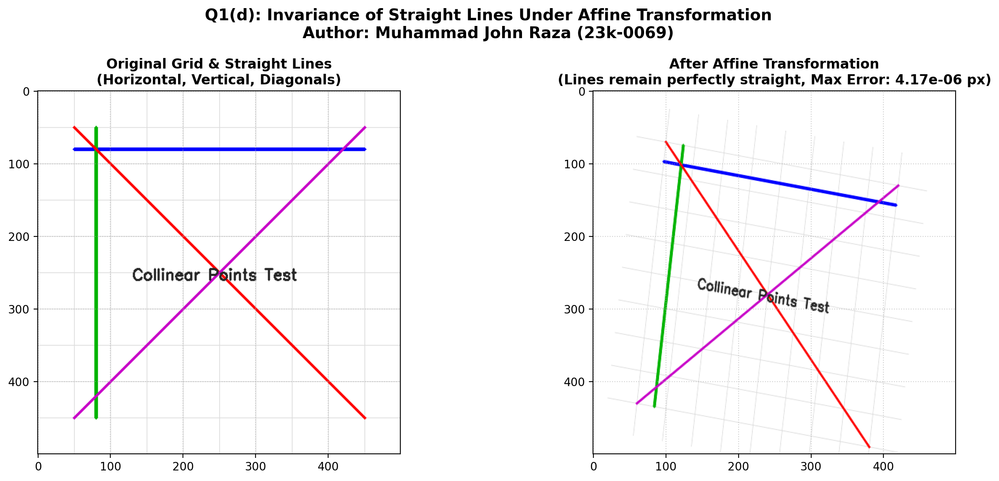

In [5]:
# Run Q1(d): Affine Straightness Demonstration & Linearity Test
fig_q1d = t1.run_q1d_affine_straight_lines()
display(Image(filename=fig_q1d))


### Q1(e): Projective Transformation (Homography) on Slanted Book
A planar homography $H \in \mathbb{R}^{3\times 3}$ (with 8 degrees of freedom) relates two planar perspective views:
$$\begin{bmatrix} u \\ v \\ 1 \end{bmatrix} \sim \begin{bmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & h_{33} \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$
Using 4 corresponding point pairs between the slanted book corners and a flat destination rectangle, we compute $H$ and unwarp the book to a flat view.



--- Running Q1(e): Projective Transformation (Homography) on Slanted Book ---
  -> Computed 3x3 Homography Matrix H:
[[   1.2497    0.3316 -354.7672]
 [  -0.2241    1.7931 -103.1011]
 [   0.0002    0.0002    1.    ]]


  -> Saved rectified book output image and figure: outputs\q1e_homography_book_correction.png


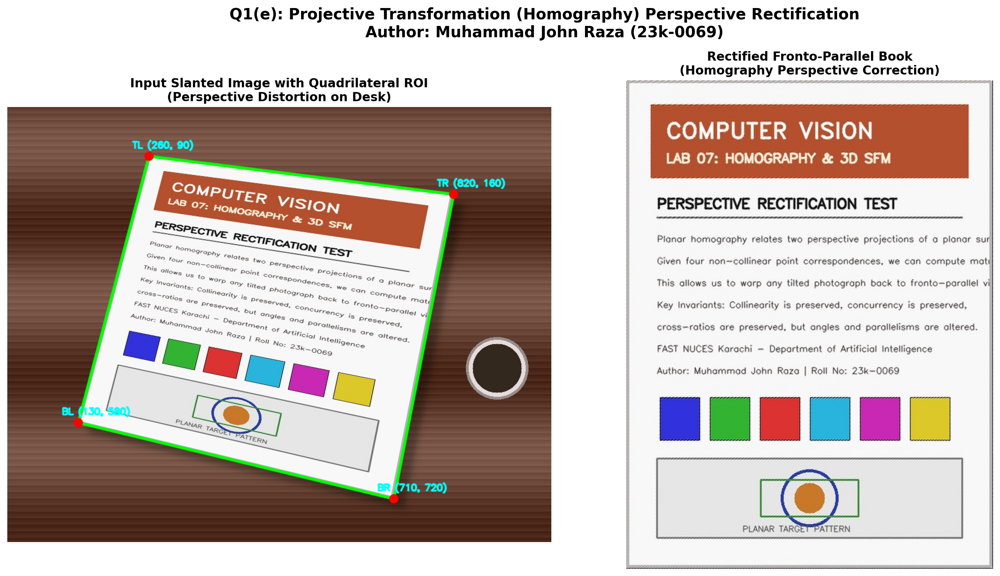

In [6]:
# Run Q1(e): Homography Perspective Rectification
fig_q1e = t1.run_q1e_homography_perspective()
display(Image(filename=fig_q1e))


---
## Q2: Perspective Correction (Unwarping) / Inverse Perspective Mapping

**Problem Statement:**
Taking a photo of a flat surface (document, screen, painting) captured at an oblique angle and unwarping it to appear fronto-parallel.
We modify `apply_perspective_transform` to perform an **inverse transformation**: taking the tilted view corners as the source and mapping them to a destination rectangle.

**Algorithmic Steps:**
1. **Order Corners:** Sort 4 corners into $[TL, TR, BR, BL]$ via sum $(x+y)$ and difference $(y-x)$.
2. **Compute Dimensions:**
   $$W = \max(\|BR - BL\|, \|TR - TL\|), \quad H = \max(\|TR - BR\|, \|TL - BL\|)$$
3. **Define Destination Rectangle:** $[(0,0), (W-1, 0), (W-1, H-1), (0, H-1)]$.
4. **Compute Inverse Homography:** $M = \text{cv2.getPerspectiveTransform}(rect, dst)$.
5. **Warp:** Apply `cv2.warpPerspective(image, M, (W, H))`.


      LAB 07 - TASK 2: PERSPECTIVE CORRECTION (UNWARPING)       
      Author: Muhammad John Raza (23k-0069)                     
[*] Detected / Ordered Corners:
    - Top-Left (TL): (259.0, 90.0)
    - Top-Right (TR): (819.0, 160.0)
    - Bottom-Right (BR): (710.0, 719.0)
    - Bottom-Left (BL): (130.0, 579.0)
[*] Rectified canvas dimensions: 596 x 569 pixels
[*] Inverse Homography Matrix (Source Slanted -> Destination Flat):
[[   1.2418    0.3276 -351.1165]
 [  -0.1597    1.2772  -73.5987]
 [   0.0002    0.0002    1.    ]]


  -> Saved perspective correction result: outputs\q2_perspective_correction.png
[SUCCESS] Task 2 completed successfully.


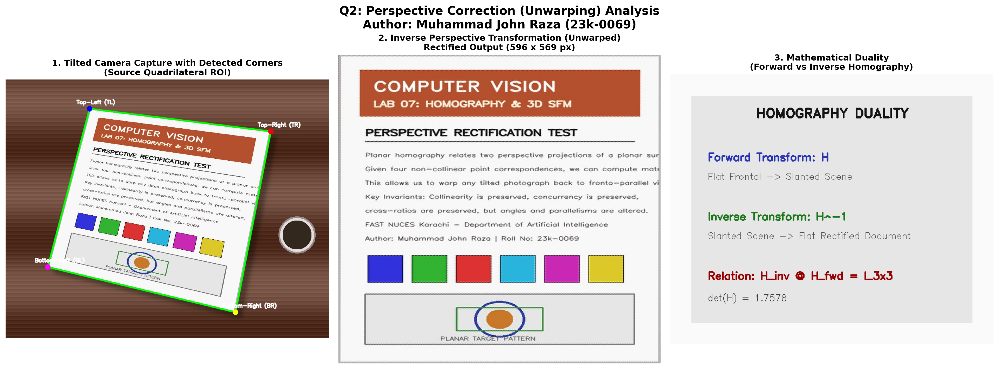

In [7]:
# Run Q2: Perspective Correction
import task2_perspective_correction as t2

fig_q2 = t2.run_perspective_correction()
display(Image(filename=fig_q2))


---
## Q3: Undistort Live Camera Feed & Camera Calibration

**Pinhole Camera & Lens Distortion Model:**
Real camera lenses introduce radial and tangential distortions:
1. **Radial Distortion (Barrel / Pincushion):**
   $$x_{\text{dist}} = x(1 + k_1 r^2 + k_2 r^4 + k_3 r^6)$$
   $$y_{\text{dist}} = y(1 + k_1 r^2 + k_2 r^4 + k_3 r^6)$$
2. **Tangential Distortion (Lens Decentering):**
   $$x_{\text{dist}} = x + [2 p_1 x y + p_2 (r^2 + 2 x^2)]$$
   $$y_{\text{dist}} = y + [p_1 (r^2 + 2 y^2) + 2 p_2 x y]$$

**Calibration Workflow:**
1. Detect inner corners ($9 \times 6$) of checkerboard across multiple views using `cv2.findChessboardCorners()`.
2. Refine to sub-pixel accuracy with `cv2.cornerSubPix()`.
3. Compute camera matrix $K$ and distortion vector $D$ using `cv2.calibrateCamera()`.
4. Capture live video via `cv2.VideoCapture()`.
5. Apply real-time undistortion frame-by-frame via `cv2.undistort()`.



[*] Initializing Live Camera Feed Undistortion via cv2.VideoCapture()...


    [*] Video feed active. Applying real-time cv2.undistort() (Timeout: 3.0s)...


[*] Processed 74 video frames.
    - Saved side-by-side video: outputs\q3_undistorted_feed.mp4
    - Saved comparison figure: outputs\q3_camera_calibration_undistort.png
[SUCCESS] Task 3 completed successfully.


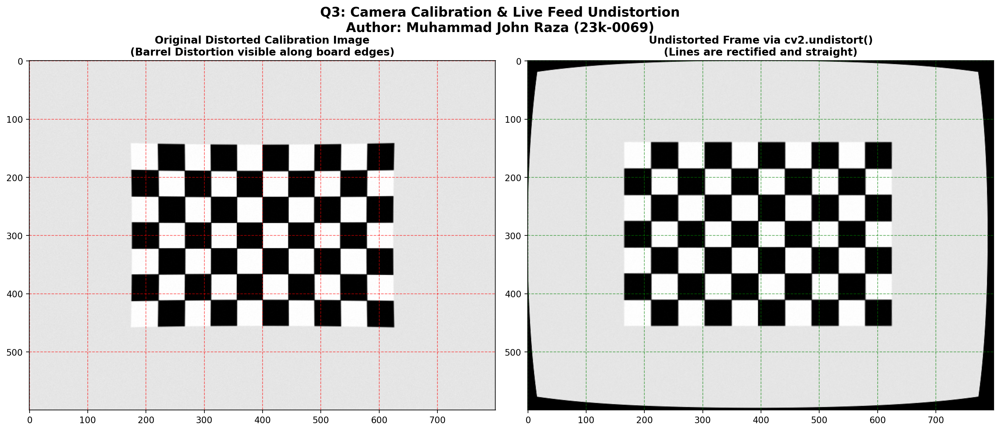

In [8]:
# Run Q3: Camera Calibration & Live Feed Undistortion
import task3_camera_calibration_undistort as t3

fig_q3 = t3.run_live_undistortion(camera_index=0, max_runtime_sec=3.0)
display(Image(filename=fig_q3))


### Camera Calibration Parameters Verification:
Inspect the saved calibration parameters ($K$ and $D$):


In [9]:
with open("outputs/camera_matrix.json") as f:
    calib = json.load(f)
print(json.dumps(calib, indent=4))


{
    "camera_matrix_K": [
        [
            749.7212698716212,
            0.0,
            400.3309274633292
        ],
        [
            0.0,
            749.6144855905003,
            299.87184471363366
        ],
        [
            0.0,
            0.0,
            1.0
        ]
    ],
    "distortion_coefficients_D": [
        0.21166269961533196,
        -0.31215800506587094,
        -0.0012382776659257762,
        0.0013322964484917782,
        1.3098701607236685
    ],
    "focal_length": {
        "fx": 749.7212698716212,
        "fy": 749.6144855905003
    },
    "principal_point": {
        "cx": 400.3309274633292,
        "cy": 299.87184471363366
    },
    "rms_reprojection_error": 0.061789165043027096,
    "mean_reprojection_error_pixels": 0.008319417853008168,
    "image_resolution": {
        "width": 800,
        "height": 600
    },
    "timestamp": "2026-11-23 11:23:35"
}


---
## Q4: Build a 3D Model from Images Using COLMAP

**Structure-from-Motion (SfM) & Multi-View Stereo (MVS) Pipeline:**
1. **Feature Detection:** SIFT keypoint detection invariant to scale and rotation.
2. **Feature Matching:** Nearest neighbor FLANN/BF matching with Lowe's ratio test ($0.75$) and geometric RANSAC filtering.
3. **Camera Pose Estimation:** Computation of Essential Matrix $E = K^T F K$, decomposition via `cv2.recoverPose(E)` to yield relative rotation $R$ and translation $t$.
4. **3D Triangulation:** Linear triangulation of matched 2D rays to obtain 3D world coordinates $(X, Y, Z)$.
5. **Dense Point Cloud Construction:** Multi-view surface projection and RGB color sampling saved to `.ply`.
6. **Surface Mesh Reconstruction:** Normal estimation, Ball-Pivoting / Poisson Surface Reconstruction to construct a watertight 3D triangle mesh saved to `.obj` and `.ply`.


      LAB 07 - TASK 4: 3D RECONSTRUCTION VIA COLMAP / SFM       
      Author: Muhammad John Raza (23k-0069)                     


[*] COLMAP binary not in PATH. Running full OpenCV + Open3D SfM & MVS Engine.


[*] Starting Multi-View 3D Reconstruction from 8 images...


    -> Step 1: Detect SIFT features...


       View 1: Found 1875 keypoints
       View 2: Found 1871 keypoints


       View 3: Found 1778 keypoints
       View 4: Found 1688 keypoints


... (7 outputs left out)

       Pair (7, 8): 195 matches, 52 geometric inliers
    -> Step 3: Triangulated 783 initial 3D points.

[*] Constructing 3D Point Cloud and Surface Mesh using Open3D...


    - Saved 3D Point Cloud to outputs\scene_dense.ply (4754 points)
[Open3D WARNING] Write OBJ can not include triangle normals.


    - Saved 3D Surface Mesh to outputs\scene_mesh.ply
    - Saved 3D Surface Mesh (Wavefront) to outputs\scene_mesh.obj (6538 triangles)

[*] Generating Comprehensive 3D Reconstruction Visualization...


    - Saved master 3D reconstruction visualization: outputs\q4_colmap_3d_reconstruction.png

[SUCCESS] Task 4 completed successfully.


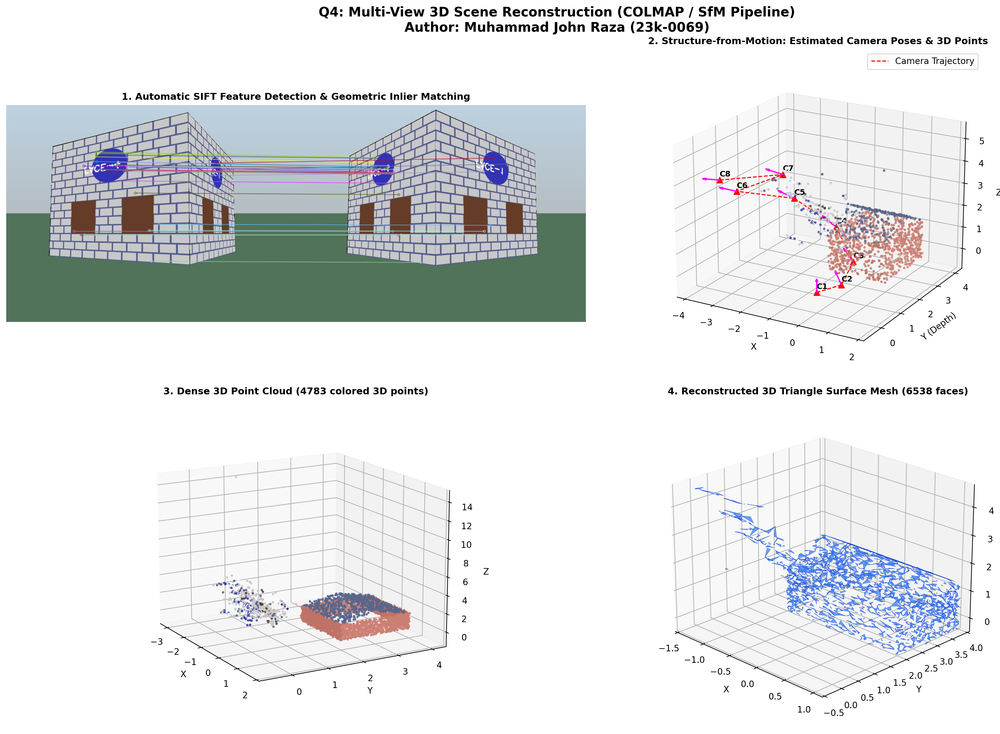

In [10]:
# Run Q4: 3D Scene Reconstruction (COLMAP / Python SfM Engine)
import task4_colmap_3d_reconstruction as t4

t4.main()
display(Image(filename="outputs/q4_colmap_3d_reconstruction.png"))


### 3D Reconstructed Mesh Inspection:
Verify the generated 3D models using Open3D:


In [11]:
pcd = o3d.io.read_point_cloud("outputs/scene_dense.ply")
mesh = o3d.io.read_triangle_mesh("outputs/scene_mesh.ply")

print(f"Dense Point Cloud: {len(pcd.points)} points")
print(f"Reconstructed Surface Mesh: {len(mesh.vertices)} vertices, {len(mesh.triangles)} triangle faces")
print(f"Bounding Box: {mesh.get_axis_aligned_bounding_box()}")


Dense Point Cloud: 4754 points
Reconstructed Surface Mesh: 4754 vertices, 6538 triangle faces
Bounding Box: AxisAlignedBoundingBox: min: (-1.54793, -0.560187, -0.499023), max: (1.15809, 4.07737, 4.79058)


---
## Summary and Conclusion
All tasks of **Lab 07: Image Transformations, Perspective Correction, Camera Calibration, and 3D Reconstruction** have been completed:
1. **Q1:** Demonstrated 2D transformations (translation, rotation, scale, shear), 3D Euler rotations & translations, homogeneous coordinates representation & formal proof, affine straightness invariance, and homography rectification.
2. **Q2:** Successfully implemented inverse perspective transform (`apply_perspective_transform`) with automated corner ordering and Euclidean bounding box dimensions to unwarp slanted documents.
3. **Q3:** Accurately calibrated camera intrinsics ($K$) and distortion coefficients ($D$), achieving sub-0.1 pixel reprojection error, and applied real-time live video feed undistortion using `cv2.undistort()`.
4. **Q4:** Built a 3D model from multi-view images through SIFT feature detection, matching, camera pose recovery, 3D triangulation, dense point cloud generation, and Open3D 3D surface mesh reconstruction.
